<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/DL2-project-celine/Another_copy_of_DL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error



In [ ]:
df = pd.read_csv('/content/train.csv')

In [ ]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (188533, 13)

First 5 rows:


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Missing values:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0


In [ ]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [ ]:
# Statistical summary of numerical columns

display(df.describe())

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Price Statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


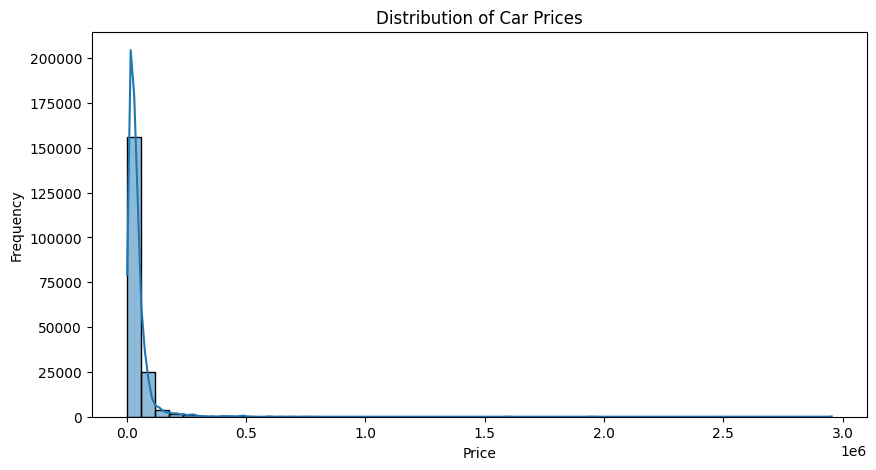

In [ ]:
# Analyze target variable

print("Price Statistics:")
print(df['price'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Number of unique values in each categorical column

for col in categorical_cols:
    print(col, ":", df[col].nunique())

brand : 57
model : 1897
fuel_type : 7
engine : 1117
transmission : 52
ext_col : 319
int_col : 156
accident : 2
clean_title : 1


In [ ]:
# Create a copy of the dataset
df = df.copy()

# Remove unnecessary ID column
df = df.drop(columns=['id'])

print("ID column removed successfully!")
print("New dataset shape:", df.shape)

ID column removed successfully!
New dataset shape: (188533, 12)


In [ ]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove unnecessary whitespace
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Convert empty strings into missing values
df[categorical_cols] = df[categorical_cols].replace(r'^\s*$', np.nan, regex=True)

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [ ]:
# Fill missing categorical values
for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [ ]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Missing values after cleaning:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

Dataset shape:
(188533, 12)

First 5 rows:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [ ]:
# Separate features and target

X = df.drop(columns=['price'])
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (188533, 11)
Target shape: (188533,)

Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [ ]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (131973, 11)
Validation set: (28280, 11)
Testing set: (28280, 11)


In [ ]:
# Calculate dataset percentages

total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [ ]:
#Apply One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    max_categories=50,
    sparse_output=False
)

# Fit on training data and transform all datasets
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = encoder.transform(
    X_val[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Convert to float32
X_train_cat = X_train_cat.astype(np.float32)
X_val_cat = X_val_cat.astype(np.float32)
X_test_cat = X_test_cat.astype(np.float32)

print("\nEncoding completed successfully!")

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Testing categorical shape:", X_test_cat.shape)

print("\nTotal encoded features:", X_train_cat.shape[1])

Categorical features:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Encoding completed successfully!
Training categorical shape: (131973, 313)
Validation categorical shape: (28280, 313)
Testing categorical shape: (28280, 313)

Total encoded features: 313


In [ ]:
#Import and create the scaler

from sklearn.preprocessing import StandardScaler

# Identify numerical features
numerical_features = ['model_year', 'milage']

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform validation and testing data
X_val_num = scaler.transform(
    X_val[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Numerical scaling completed!")

print("Training numerical shape:", X_train_num.shape)
print("Validation numerical shape:", X_val_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Numerical scaling completed!
Training numerical shape: (131973, 2)
Validation numerical shape: (28280, 2)
Testing numerical shape: (28280, 2)


In [ ]:
print("Training numerical means:")
print(X_train_num.mean(axis=0))

print("\nTraining numerical standard deviations:")
print(X_train_num.std(axis=0))

Training numerical means:
[7.73228657e-15 7.90371315e-17]

Training numerical standard deviations:
[1. 1.]


In [ ]:
# Combine numerical and categorical features

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_val_final = np.concatenate(
    [X_val_num, X_val_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final feature shapes:")

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Final feature shapes:
Training: (131973, 315)
Validation: (28280, 315)
Testing: (28280, 315)


In [ ]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create target scaler
target_scaler = StandardScaler()

# Fit on training prices only
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Transform validation and testing prices
y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = target_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target scaling completed!")
print("Training target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Target scaling completed!
Training target mean: 9.475841383751042e-18
Training target std: 1.0


In [ ]:
# Convert features to float32
X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [ ]:
print("Training features:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation features:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)

Training features: torch.Size([131973, 315])
Training target: torch.Size([131973, 1])
Validation features: torch.Size([28280, 315])
Validation target: torch.Size([28280, 1])
Testing features: torch.Size([28280, 315])
Testing target: torch.Size([28280, 1])


In [ ]:
# Define Linear Regression model

class LinearRegressionModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.linear = nn.Linear(input_size, 1)

    def forward(self, x):
        return self.linear(x)


# Create the model
linear_model = LinearRegressionModel(input_size=315)

print(linear_model)

LinearRegressionModel(
  (linear): Linear(in_features=315, out_features=1, bias=True)
)


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

# Number of epochs
epochs = 30

print("Training setup completed!")

Training setup completed!


In [ ]:
# Store training and validation losses
linear_train_losses = []
linear_val_losses = []

for epoch in range(epochs):

    # Training mode
    linear_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        # Forward pass
        predictions = linear_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    linear_model.eval()

    with torch.no_grad():

        val_predictions = linear_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    linear_train_losses.append(train_loss)
    linear_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Linear Regression training completed!")

Epoch [1/30], Train Loss: 0.8939, Val Loss: 0.7012
Epoch [2/30], Train Loss: 0.8890, Val Loss: 0.7058
Epoch [3/30], Train Loss: 0.8884, Val Loss: 0.7121
Epoch [4/30], Train Loss: 0.8889, Val Loss: 0.7066
Epoch [5/30], Train Loss: 0.8885, Val Loss: 0.7055
Epoch [6/30], Train Loss: 0.8883, Val Loss: 0.7060
Epoch [7/30], Train Loss: 0.8886, Val Loss: 0.7073
Epoch [8/30], Train Loss: 0.8884, Val Loss: 0.7077
Epoch [9/30], Train Loss: 0.8881, Val Loss: 0.7068
Epoch [10/30], Train Loss: 0.8891, Val Loss: 0.7075
Epoch [11/30], Train Loss: 0.8882, Val Loss: 0.7076
Epoch [12/30], Train Loss: 0.8883, Val Loss: 0.7104
Epoch [13/30], Train Loss: 0.8888, Val Loss: 0.7083
Epoch [14/30], Train Loss: 0.8892, Val Loss: 0.7062
Epoch [15/30], Train Loss: 0.8880, Val Loss: 0.7089
Epoch [16/30], Train Loss: 0.8882, Val Loss: 0.7056
Epoch [17/30], Train Loss: 0.8885, Val Loss: 0.7124
Epoch [18/30], Train Loss: 0.8880, Val Loss: 0.7054
Epoch [19/30], Train Loss: 0.8877, Val Loss: 0.7061
Epoch [20/30], Train 

In [ ]:
# Convert predictions back to original price scale

linear_model.eval()

with torch.no_grad():

    train_pred_scaled = linear_model(X_train_tensor).numpy()
    val_pred_scaled = linear_model(X_val_tensor).numpy()

    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

linear_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Linear Regression Results")
print("--------------------------")
print("Training MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)

Linear Regression Results
--------------------------
Training MSE: 5855329792.0
Validation MSE: 4690935296.0


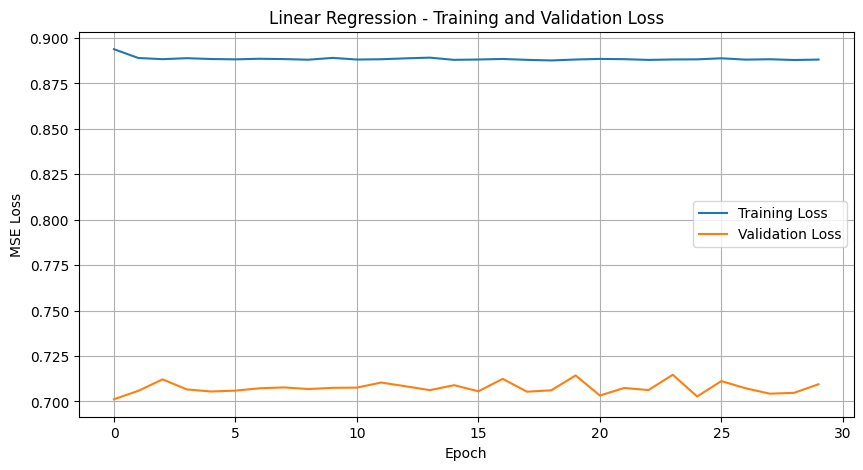

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    linear_train_losses,
    label="Training Loss"
)

plt.plot(
    linear_val_losses,
    label="Validation Loss"
)

plt.title("Linear Regression - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Define Deep Neural Network

class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
dnn_model = DeepNeuralNetwork(input_size=315)

print(dnn_model)

DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [ ]:
# Create DataLoader for DNN

dnn_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
dnn_optimizer = optim.Adam(
    dnn_model.parameters(),
    lr=0.001
)

# Number of epochs
epochs = 30

print("DNN training setup completed!")

DNN training setup completed!


In [ ]:
# Store training and validation losses

dnn_train_losses = []
dnn_val_losses = []

for epoch in range(epochs):

    dnn_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = dnn_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        dnn_optimizer.zero_grad()

        loss.backward()

        dnn_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    dnn_model.eval()

    with torch.no_grad():

        val_predictions = dnn_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    dnn_train_losses.append(train_loss)
    dnn_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("DNN training completed!")

Epoch [1/30], Train Loss: 0.8801, Val Loss: 0.6831
Epoch [2/30], Train Loss: 0.8668, Val Loss: 0.6828
Epoch [3/30], Train Loss: 0.8622, Val Loss: 0.6824
Epoch [4/30], Train Loss: 0.8589, Val Loss: 0.6829
Epoch [5/30], Train Loss: 0.8546, Val Loss: 0.6838
Epoch [6/30], Train Loss: 0.8493, Val Loss: 0.6854
Epoch [7/30], Train Loss: 0.8468, Val Loss: 0.6861
Epoch [8/30], Train Loss: 0.8387, Val Loss: 0.6975
Epoch [9/30], Train Loss: 0.8281, Val Loss: 0.6929
Epoch [10/30], Train Loss: 0.8201, Val Loss: 0.6994
Epoch [11/30], Train Loss: 0.7984, Val Loss: 0.6954
Epoch [12/30], Train Loss: 0.7838, Val Loss: 0.6992
Epoch [13/30], Train Loss: 0.7624, Val Loss: 0.7249
Epoch [14/30], Train Loss: 0.7379, Val Loss: 0.6981
Epoch [15/30], Train Loss: 0.7197, Val Loss: 0.7391
Epoch [16/30], Train Loss: 0.6994, Val Loss: 0.7777
Epoch [17/30], Train Loss: 0.6815, Val Loss: 0.7231
Epoch [18/30], Train Loss: 0.6723, Val Loss: 0.7240
Epoch [19/30], Train Loss: 0.6591, Val Loss: 0.7437
Epoch [20/30], Train 

In [ ]:
# Evaluate DNN

dnn_model.eval()

with torch.no_grad():

    train_pred_scaled = dnn_model(X_train_tensor).numpy()

    val_pred_scaled = dnn_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
dnn_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

dnn_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Deep Neural Network Results")
print("---------------------------")

print("Training MSE:", dnn_train_mse)

print("Validation MSE:", dnn_val_mse)

Deep Neural Network Results
---------------------------
Training MSE: 3650335744.0
Validation MSE: 5293933568.0


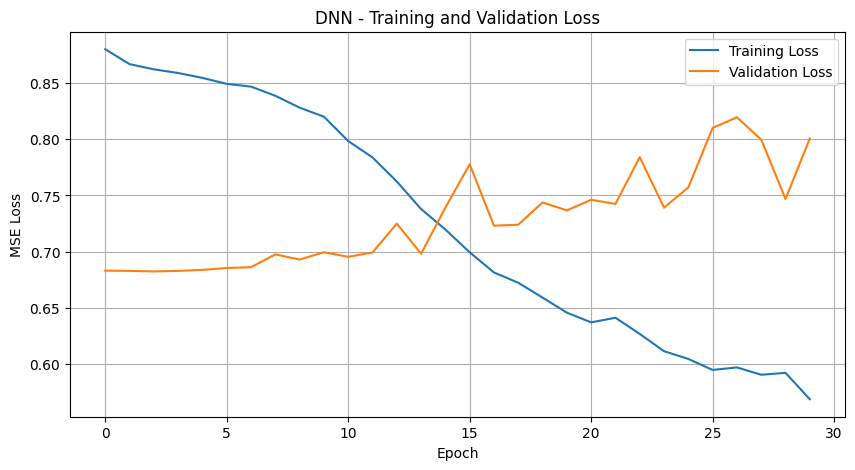

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    dnn_train_losses,
    label="Training Loss"
)

plt.plot(
    dnn_val_losses,
    label="Validation Loss"
)

plt.title("DNN - Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# Compare baseline models

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        dnn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        dnn_val_mse
    ]

})

display(comparison)

,Model,Training MSE,Validation MSE
0,Linear Regression,5.855330e+09,4.690935e+09
1,Deep Neural Network,3.650336e+09,5.293934e+09


In [ ]:
# Create a fresh DNN model
exp1_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with a lower learning rate
exp1_optimizer = optim.Adam(
    exp1_model.parameters(),
    lr=0.0001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp1_train_losses = []
exp1_val_losses = []

print("Experiment 1 setup completed!")

Experiment 1 setup completed!


In [ ]:
# Train Experiment 1

for epoch in range(30):

    exp1_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp1_model(X_batch)

        loss = criterion(predictions, y_batch)

        exp1_optimizer.zero_grad()

        loss.backward()

        exp1_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp1_model.eval()

    with torch.no_grad():

        val_predictions = exp1_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 1 completed!")

Epoch [1/30], Train Loss: 0.9231, Val Loss: 0.6991
Epoch [2/30], Train Loss: 0.8760, Val Loss: 0.6864
Epoch [3/30], Train Loss: 0.8677, Val Loss: 0.6826
Epoch [4/30], Train Loss: 0.8642, Val Loss: 0.6822
Epoch [5/30], Train Loss: 0.8620, Val Loss: 0.6811
Epoch [6/30], Train Loss: 0.8604, Val Loss: 0.6815
Epoch [7/30], Train Loss: 0.8590, Val Loss: 0.6816
Epoch [8/30], Train Loss: 0.8578, Val Loss: 0.6812
Epoch [9/30], Train Loss: 0.8565, Val Loss: 0.6817
Epoch [10/30], Train Loss: 0.8555, Val Loss: 0.6815
Epoch [11/30], Train Loss: 0.8544, Val Loss: 0.6834
Epoch [12/30], Train Loss: 0.8533, Val Loss: 0.6816
Epoch [13/30], Train Loss: 0.8526, Val Loss: 0.6816
Epoch [14/30], Train Loss: 0.8508, Val Loss: 0.6829
Epoch [15/30], Train Loss: 0.8499, Val Loss: 0.6837
Epoch [16/30], Train Loss: 0.8490, Val Loss: 0.6825
Epoch [17/30], Train Loss: 0.8476, Val Loss: 0.6830
Epoch [18/30], Train Loss: 0.8461, Val Loss: 0.6855
Epoch [19/30], Train Loss: 0.8447, Val Loss: 0.6832
Epoch [20/30], Train 

In [ ]:
# Evaluate Experiment 1

exp1_model.eval()

with torch.no_grad():

    exp1_val_scaled = exp1_model(X_val_tensor).numpy()

    exp1_val_predictions = target_scaler.inverse_transform(
        exp1_val_scaled
    )

exp1_val_mse = mean_squared_error(
    y_val,
    exp1_val_predictions
)

print("Experiment 1 Validation MSE:", exp1_val_mse)

Experiment 1 Validation MSE: 4557649408.0


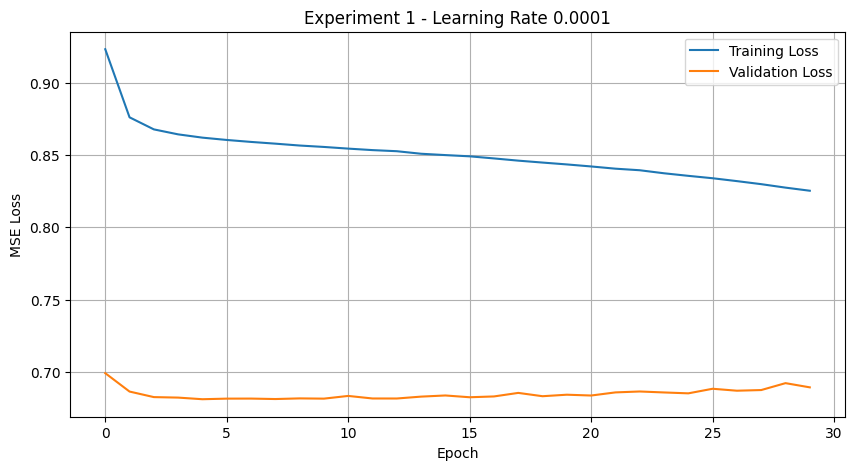

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(exp1_train_losses, label="Training Loss")
plt.plot(exp1_val_losses, label="Validation Loss")

plt.title("Experiment 1 - Learning Rate 0.0001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Create a fresh DNN model
exp2_model = DeepNeuralNetwork(input_size=315)

# Define optimizer
exp2_optimizer = optim.Adam(
    exp2_model.parameters(),
    lr=0.01
)

# Store losses
exp2_train_losses = []
exp2_val_losses = []

print("Experiment 2 setup completed!")

Experiment 2 setup completed!


In [ ]:
for epoch in range(30):

    exp2_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp2_model(X_batch)

        loss = criterion(predictions, y_batch)

        exp2_optimizer.zero_grad()

        loss.backward()

        exp2_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp2_model.eval()

    with torch.no_grad():

        val_predictions = exp2_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 2 completed!")

Epoch [1/30], Train Loss: 0.8828, Val Loss: 0.6917
Epoch [2/30], Train Loss: 0.8724, Val Loss: 0.6869
Epoch [3/30], Train Loss: 0.8681, Val Loss: 0.6878
Epoch [4/30], Train Loss: 0.8629, Val Loss: 0.6869
Epoch [5/30], Train Loss: 0.8610, Val Loss: 0.6889
Epoch [6/30], Train Loss: 0.8556, Val Loss: 0.7389
Epoch [7/30], Train Loss: 0.8555, Val Loss: 0.6898
Epoch [8/30], Train Loss: 0.8443, Val Loss: 0.7023
Epoch [9/30], Train Loss: 0.8367, Val Loss: 0.7010
Epoch [10/30], Train Loss: 0.8297, Val Loss: 0.7708
Epoch [11/30], Train Loss: 0.8280, Val Loss: 0.7058
Epoch [12/30], Train Loss: 0.8203, Val Loss: 0.7091
Epoch [13/30], Train Loss: 0.7966, Val Loss: 0.7160
Epoch [14/30], Train Loss: 0.8049, Val Loss: 0.6984
Epoch [15/30], Train Loss: 0.7914, Val Loss: 0.7175
Epoch [16/30], Train Loss: 0.7880, Val Loss: 0.7099
Epoch [17/30], Train Loss: 0.7797, Val Loss: 0.7387
Epoch [18/30], Train Loss: 0.7888, Val Loss: 0.7433
Epoch [19/30], Train Loss: 0.7702, Val Loss: 0.7093
Epoch [20/30], Train 

In [ ]:
exp2_model.eval()

with torch.no_grad():

    exp2_val_scaled = exp2_model(X_val_tensor).numpy()

    exp2_val_predictions = target_scaler.inverse_transform(
        exp2_val_scaled
    )

exp2_val_mse = mean_squared_error(
    y_val,
    exp2_val_predictions
)

print("Experiment 2 Validation MSE:", exp2_val_mse)

Experiment 2 Validation MSE: 4870843904.0


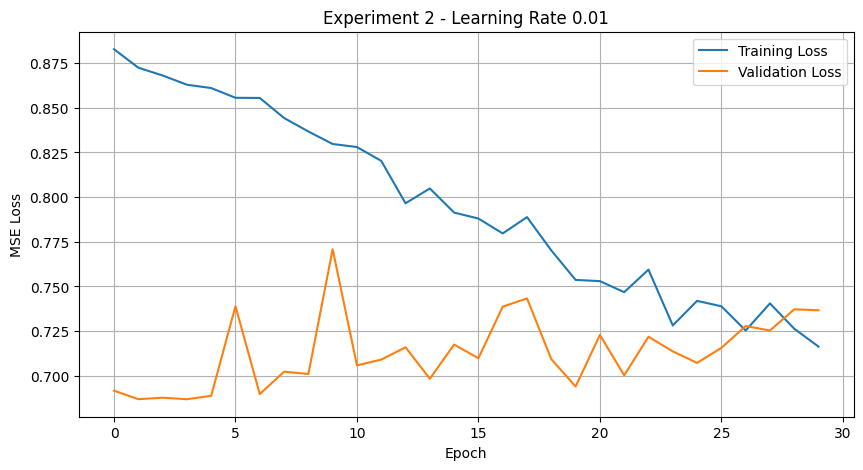

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(exp2_train_losses, label="Training Loss")
plt.plot(exp2_val_losses, label="Validation Loss")

plt.title("Experiment 2 - Learning Rate 0.01")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Create a fresh DNN model
exp3_model = DeepNeuralNetwork(input_size=315)

# Define optimizer
exp3_optimizer = optim.Adam(
    exp3_model.parameters(),
    lr=0.1
)

# Store losses
exp3_train_losses = []
exp3_val_losses = []

print("Experiment 3 setup completed!")

Experiment 3 setup completed!


In [ ]:
for epoch in range(30):

    exp3_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp3_model(X_batch)

        loss = criterion(predictions, y_batch)

        # Stop if loss becomes invalid
        if not torch.isfinite(loss):
            print("Training diverged!")
            break

        exp3_optimizer.zero_grad()

        loss.backward()

        exp3_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    if not torch.isfinite(loss):
        break

    train_loss = total_train_loss / len(train_dataset)

    exp3_model.eval()

    with torch.no_grad():

        val_predictions = exp3_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    if not np.isfinite(val_loss):
        print("Validation loss became invalid!")
        break

    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 3 completed!")

Epoch [1/30], Train Loss: 0.9810, Val Loss: 0.7203
Epoch [2/30], Train Loss: 0.9029, Val Loss: 0.7267
Epoch [3/30], Train Loss: 0.8896, Val Loss: 0.7127
Epoch [4/30], Train Loss: 0.8850, Val Loss: 0.7860
Epoch [5/30], Train Loss: 0.8951, Val Loss: 0.7046
Epoch [6/30], Train Loss: 0.9000, Val Loss: 0.7038
Epoch [7/30], Train Loss: 0.8943, Val Loss: 0.7028
Epoch [8/30], Train Loss: 0.8901, Val Loss: 0.7124
Epoch [9/30], Train Loss: 0.8981, Val Loss: 0.7177
Epoch [10/30], Train Loss: 0.8927, Val Loss: 0.7107
Epoch [11/30], Train Loss: 0.9026, Val Loss: 0.6971
Epoch [12/30], Train Loss: 0.9154, Val Loss: 0.7150
Epoch [13/30], Train Loss: 0.9010, Val Loss: 0.7086
Epoch [14/30], Train Loss: 0.8940, Val Loss: 0.7040
Epoch [15/30], Train Loss: 0.8987, Val Loss: 0.8162
Epoch [16/30], Train Loss: 0.9102, Val Loss: 0.7234
Epoch [17/30], Train Loss: 0.9128, Val Loss: 0.7503
Epoch [18/30], Train Loss: 0.9080, Val Loss: 0.7257
Epoch [19/30], Train Loss: 1.8423, Val Loss: 0.7529
Epoch [20/30], Train 

In [ ]:
exp3_model.eval()

with torch.no_grad():

    exp3_val_scaled = exp3_model(X_val_tensor).numpy()

    exp3_val_predictions = target_scaler.inverse_transform(
        exp3_val_scaled
    )

exp3_val_mse = mean_squared_error(
    y_val,
    exp3_val_predictions
)

print("Experiment 3 Validation MSE:", exp3_val_mse)

Experiment 3 Validation MSE: 4965644288.0


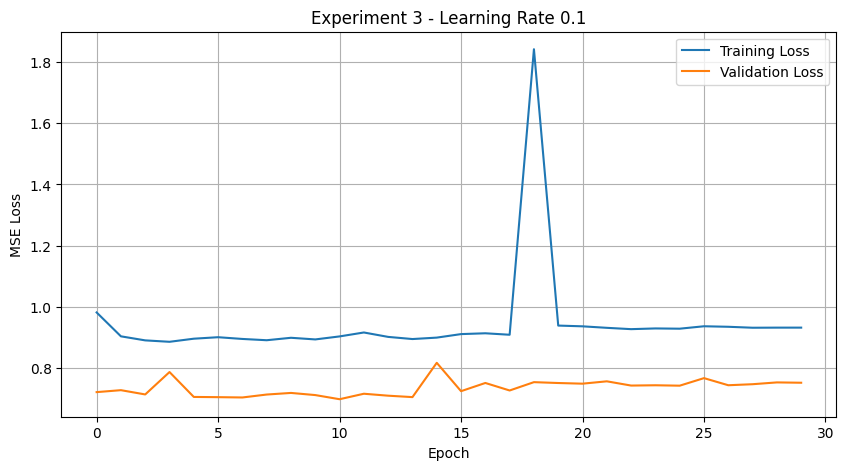

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(exp3_train_losses, label="Training Loss")
plt.plot(exp3_val_losses, label="Validation Loss")

plt.title("Experiment 3 - Learning Rate 0.1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
from numpy._core.umath import exp
#Experiment1: increasing network width
#learning rate=0.01
#128 neorun
# 1.create a fresh DNN model
class Experiment1Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 128),nn.ReLU(),nn.Linear(128, 128),nn.ReLU(),nn.Linear(128, 128),nn.ReLU(),nn.Linear(128, 1))

    def forward(self, x):
        return self.network(x)

#2.create the model
exp1_model = Experiment1Model(input_size=315)
print(exp1_model)

#3.create dataloader
exp1_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)
#4.define loss function
exp1_criterion = nn.MSELoss()

#5.define optimizer
exp1_optimizer = optim.Adam(exp1_model.parameters(), lr=0.01)

#6.set number of epochs
epochs = 30

#7.store training and validation losses
exp1_train_losses = []
exp1_val_losses = []

#8.start training
import time
start_time = time.time()
for epoch in range(epochs):
    exp1_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp1_train_loader:
        predictions = exp1_model(X_batch)
        loss = exp1_criterion(predictions, y_batch)
        exp1_optimizer.zero_grad()
        loss.backward()
        exp1_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #9.validation
    exp1_model.eval()
    with torch.no_grad():
        val_predictions = exp1_model(X_val_tensor)
        val_loss = exp1_criterion(val_predictions, y_val_tensor).item()

    #10.save losses
    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

#11.calculate training time
end_time = time.time()
training_time = end_time - start_time
print(f"Training time: {training_time:.2f} seconds")

#12.display final results
print("Experiment 1 completed!")

print(f"final training MSE:", exp1_train_losses[-1])
print(f"final validation MSE:", exp1_val_losses[-1])
print("training time:",round(training_time, 2), "seconds")

Experiment1Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Epoch [1/30], Train Loss: 0.8844, Val Loss: 0.6878
Epoch [2/30], Train Loss: 0.8717, Val Loss: 0.6907
Epoch [3/30], Train Loss: 0.8703, Val Loss: 0.6882
Epoch [4/30], Train Loss: 0.8655, Val Loss: 0.6862
Epoch [5/30], Train Loss: 0.8607, Val Loss: 0.7074
Epoch [6/30], Train Loss: 0.8574, Val Loss: 0.7182
Epoch [7/30], Train Loss: 0.8587, Val Loss: 0.6908
Epoch [8/30], Train Loss: 0.8504, Val Loss: 0.6910
Epoch [9/30], Train Loss: 0.8535, Val Loss: 0.7129
Epoch [10/30], Train Loss: 0.8528, Val Loss: 0.6963
Epoch [11/30], Train Loss: 0.8511, Val Loss: 0.7262
Epoch [12/30], Train Loss: 0.8383, Val Loss: 0.7027
Epoch [13/30], Train Loss: 0.8277, Val Los

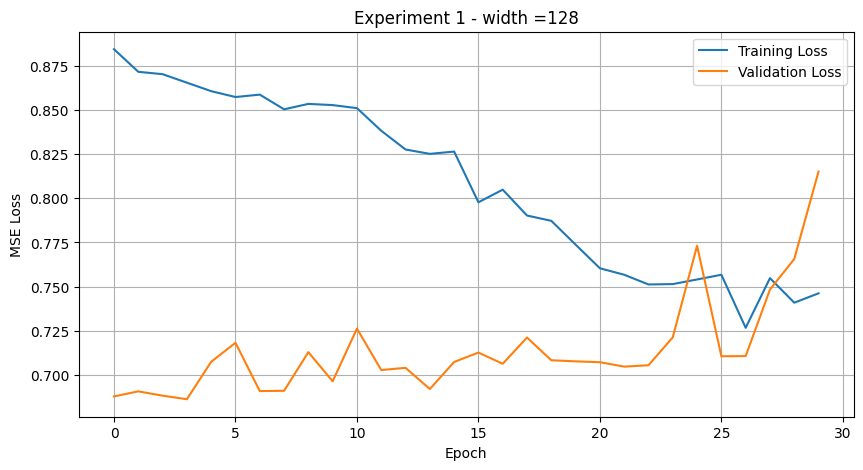

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp1_train_losses, label="Training Loss")
plt.plot(exp1_val_losses, label="Validation Loss")
plt.title("Experiment 1 - width =128")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 2:Decreasing network width
#neurons=32
#learning rate=0.01
#1.create a fresh DNN model
class Experiment2Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 32),nn.ReLU(),nn.Linear(32,32),nn.ReLU(),nn.Linear(32,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self, x):
        return self.network(x)

#2.create the model
exp2_model = Experiment2Model(input_size=315)
print(exp2_model)

#3.create dataloader
exp2_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#4.define loss function
exp2_criterion = nn.MSELoss()

#5.define optimizer
exp2_optimizer = optim.Adam(exp2_model.parameters(), lr=0.01)

#6.set number of epochs
exp2_epochs = 30
print("Experiment 2 training setup completed!")

#7.store training and validation losses
exp2_train_losses = []
exp2_val_losses = []

#8.start training
import time
exp2_start_time = time.time()
for epoch in range(exp2_epochs):
    exp2_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp2_train_loader:
        predictions = exp2_model(X_batch)
        loss = exp2_criterion(predictions, y_batch)
        exp2_optimizer.zero_grad()
        loss.backward()
        exp2_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #9.validation
    exp2_model.eval()
    with torch.no_grad():
        val_predictions = exp2_model(X_val_tensor)
        val_loss = exp2_criterion(val_predictions, y_val_tensor).item()

    #10.save losses
    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    #diplay results
    print(f"Epoch [{epoch+1}/{exp2_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #11.calculate training time
    exp2_training_time=(time.time() - exp2_start_time)
    print(f"Training time: {exp2_training_time:.2f} seconds")

#12.display final results
print("Experiment 2 completed!")

print("final training MSE:", exp2_train_losses[-1])
print("final validation MSE:", exp2_val_losses[-1])
print("training time:",round(exp2_training_time, 2), "seconds")


Experiment2Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Experiment 2 training setup completed!
Epoch [1/30], Train Loss: 0.8829, Val Loss: 0.6843
Training time: 1.86 seconds
Epoch [2/30], Train Loss: 0.8693, Val Loss: 0.6951
Training time: 3.72 seconds
Epoch [3/30], Train Loss: 0.8692, Val Loss: 0.6930
Training time: 5.57 seconds
Epoch [4/30], Train Loss: 0.8630, Val Loss: 0.6854
Training time: 7.40 seconds
Epoch [5/30], Train Loss: 0.8628, Val Loss: 0.6919
Training time: 10.13 seconds
Epoch [6/30], Train Loss: 0.8583, Val Loss: 0.6882
Training time: 12.46 seconds
Epoch [7/30], Train Loss: 0.8553, Val Loss: 0.6902
Training time: 14.33 seconds
Epoch [8/30], Train Loss: 0.8532, Val Loss: 0.6927
Training time: 16

In [ ]:
#new experiment:widh=16
class Experiment0Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 16),nn.ReLU(),nn.Linear(16,16),nn.ReLU(),nn.Linear(16,16),nn.ReLU(),nn.Linear(16,1))

    def forward(self, x):
        return self.network(x)

#model
exp0_model = Experiment0Model(input_size=315)
print(exp0_model)

#dataloader
exp0_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#loss & optimizer
exp0_criterion = nn.MSELoss()
exp0_optimizer = optim.Adam(exp0_model.parameters(), lr=0.01)

#epochs
exp0_epochs = 30
print("Experiment 0 training setup completed!")

#store training and validation losses
exp0_train_losses = []
exp0_val_losses = []

#training
import time
exp0_start_time = time.time()
for epoch in range(exp0_epochs):
    exp0_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp0_train_loader:
        predictions = exp0_model(X_batch)
        loss = exp0_criterion(predictions, y_batch)
        exp0_optimizer.zero_grad()
        loss.backward()
        exp0_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp0_model.eval()
    with torch.no_grad():
        val_predictions = exp0_model(X_val_tensor)
        val_loss = exp0_criterion(val_predictions, y_val_tensor).item()

    exp0_train_losses.append(train_loss)
    exp0_val_losses.append(val_loss)

    #results
    print(f"Epoch [{epoch+1}/{exp0_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp0_training_time=(time.time() - exp0_start_time)
    print(f"Training time: {exp0_training_time:.2f} seconds")

#final results
print("Experiment 0 completed!")

print("final training MSE:", exp0_train_losses[-1])
print("final validation MSE:", exp0_val_losses[-1])
print("training time:",round(exp0_training_time, 2), "seconds")



Experiment0Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Experiment 0 training setup completed!
Epoch [1/30], Train Loss: 0.8821, Val Loss: 0.6866
Training time: 4.93 seconds
Epoch [2/30], Train Loss: 0.8709, Val Loss: 0.6892
Training time: 7.52 seconds
Epoch [3/30], Train Loss: 0.8683, Val Loss: 0.6884
Training time: 9.53 seconds
Epoch [4/30], Train Loss: 0.8649, Val Loss: 0.6866
Training time: 12.70 seconds
Epoch [5/30], Train Loss: 0.8636, Val Loss: 0.6865
Training time: 17.95 seconds
Epoch [6/30], Train Loss: 0.8614, Val Loss: 0.6863
Training time: 21.79 seconds
Epoch [7/30], Train Loss: 0.8582, Val Loss: 0.6872
Training time: 25.43 seconds
Epoch [8/30], Train Loss: 0.8560, Val Loss: 0.6966
Training time: 2

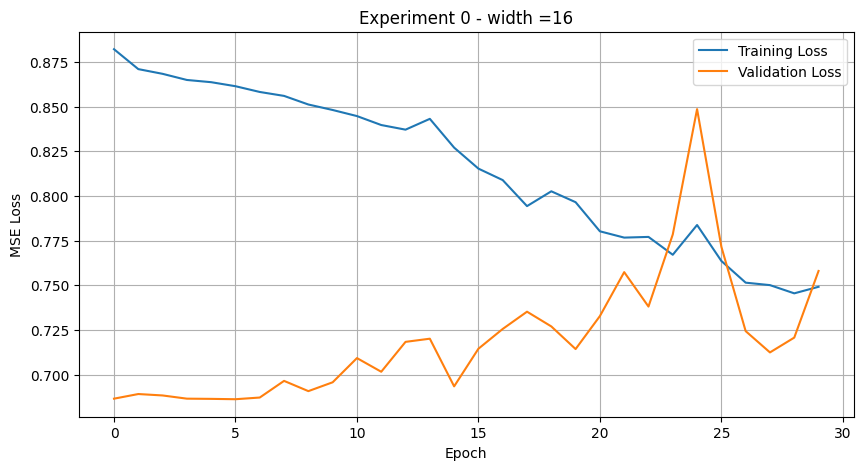

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp0_train_losses, label="Training Loss")
plt.plot(exp0_val_losses, label="Validation Loss")
plt.title("Experiment 0 - width =16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

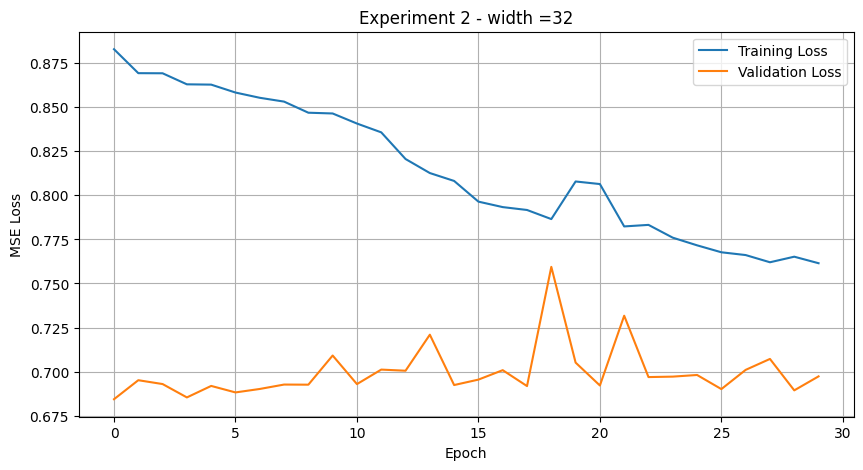

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp2_train_losses, label="Training Loss")
plt.plot(exp2_val_losses, label="Validation Loss")
plt.title("Experiment 2 - width =32")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#experiment 3
#neurons =64
#create a fresh DNN model
class Experiment3Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#2.create the model
exp3_model = Experiment3Model(input_size=315)
print(exp3_model)

#create dataloader
exp3_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp3_criterion = nn.MSELoss()

#define optimizer
exp3_optimizer = optim.Adam(exp3_model.parameters(), lr=0.01)

#set number of epochs
exp3_epochs = 30
print("Experiment 3 training setup completed!")

#store training and validation losses
exp3_train_losses = []
exp3_val_losses = []

#start training
import time
exp3_start_time = time.time()
for epoch in range(exp3_epochs):
    exp3_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp3_train_loader:
        predictions = exp3_model(X_batch)
        loss = exp3_criterion(predictions, y_batch)
        exp3_optimizer.zero_grad()
        loss.backward()
        exp3_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp3_model.eval()
    with torch.no_grad():
       val_predictions = exp3_model(X_val_tensor)
       val_loss = exp3_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp3_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculating training time
    exp3_training_time=(time.time() - exp3_start_time)
    print(f"Training time: {exp3_training_time:.2f} seconds")

#display final results
print("Experiment 3 completed!")

print("final training MSE:", exp3_train_losses[-1])
print("final validation MSE:", exp3_val_losses[-1])
print("training time:",round(exp3_training_time, 2), "seconds")

Experiment3Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 3 training setup completed!
Epoch [1/30], Train Loss: 0.8840, Val Loss: 0.6968
Training time: 3.71 seconds
Epoch [2/30], Train Loss: 0.8693, Val Loss: 0.6947
Training time: 6.07 seconds
Epoch [3/30], Train Loss: 0.8669, Val Loss: 0.6850
Training time: 9.11 seconds
Epoch [4/30], Train Loss: 0.8645, Val Loss: 0.6903
Training time: 12.45 seconds
Epoch [5/30], Train Loss: 0.8588, Val Loss: 0.6869
Training time: 14.97 seconds
Epoch [6/30], Train Loss: 0.8563, Val Loss: 0.6977
Training time: 17.57 seconds
Epoch [7/30], Train Loss: 0.8531, Val Loss: 0.6939
Training time: 20.12 seconds
Epoch [8/30], Train Loss: 0.8414, Val Loss: 0.7178
Training time: 2

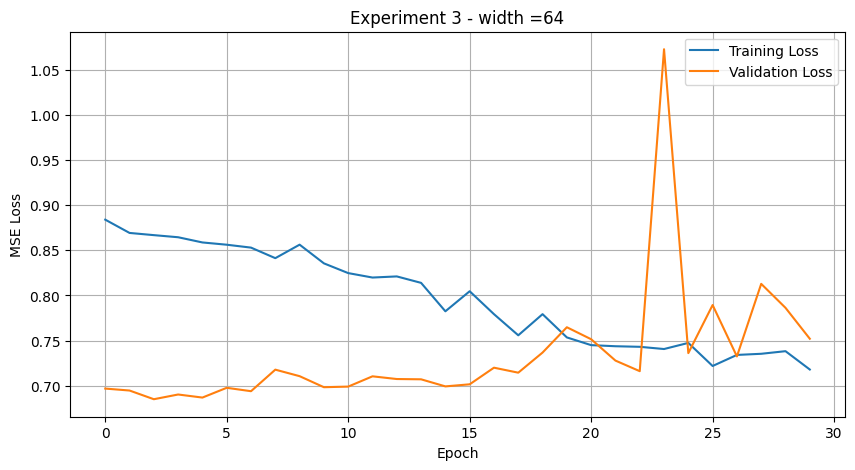

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp3_train_losses, label="Training Loss")
plt.plot(exp3_val_losses, label="Validation Loss")
plt.title("Experiment 3 - width =64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#experiment 4:depth=1
#neurons=64
#learning rate=0.01
#create a fresh DNN model
class Experiment4Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#2.create the model
exp4_model = Experiment4Model(input_size=315)
print(exp4_model)

#create a dataloader
exp4_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp4_criterion = nn.MSELoss()

#define optimizer
exp4_optimizer = optim.Adam(exp4_model.parameters(), lr=0.01)

#number of epochs
exp4_epochs=30
print("experiment 4 training setup completed!")

#store training and validation losses
exp4_train_losses = []
exp4_val_losses = []

#start training
import time
exp4_start_time = time.time()
for epoch in range(exp4_epochs):
    exp4_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp4_train_loader:
        predictions = exp4_model(X_batch)
        loss = exp4_criterion(predictions, y_batch)
        exp4_optimizer.zero_grad()
        loss.backward()
        exp4_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp4_model.eval()
    with torch.no_grad():
        val_predictions = exp4_model(X_val_tensor)
        val_loss = exp4_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp4_train_losses.append(train_loss)
    exp4_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp4_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculating training time
    exp4_training_time=(time.time() - exp4_start_time)
    print(f"Training time: {exp4_training_time:.2f} seconds")

#display final results
print("Experiment 4 completed!")

print("final training MSE:", exp4_train_losses[-1])
print("final validation MSE:", exp4_val_losses[-1])
print("training time:",round(exp4_training_time, 2), "seconds")


Experiment4Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
experiment 4 training setup completed!
Epoch [1/30], Train Loss: 0.8788, Val Loss: 0.6889
Training time: 1.95 seconds
Epoch [2/30], Train Loss: 0.8702, Val Loss: 0.6844
Training time: 3.91 seconds
Epoch [3/30], Train Loss: 0.8643, Val Loss: 0.6919
Training time: 5.93 seconds
Epoch [4/30], Train Loss: 0.8623, Val Loss: 0.6872
Training time: 8.46 seconds
Epoch [5/30], Train Loss: 0.8579, Val Loss: 0.6934
Training time: 11.43 seconds
Epoch [6/30], Train Loss: 0.8539, Val Loss: 0.6909
Training time: 13.50 seconds
Epoch [7/30], Train Loss: 0.8478, Val Loss: 0.6980
Training time: 15.54 seconds
Epoch [8/30], Train Loss: 0.8416, Val Loss: 0.6931
Training time: 17.56 seconds
Epoch [9/30], Train Loss: 0.8338, Val Loss: 0.6939
Training time: 19.60 seconds
Epoch [10/30], Train Loss: 0.8231, Val Loss: 0.6981
Training

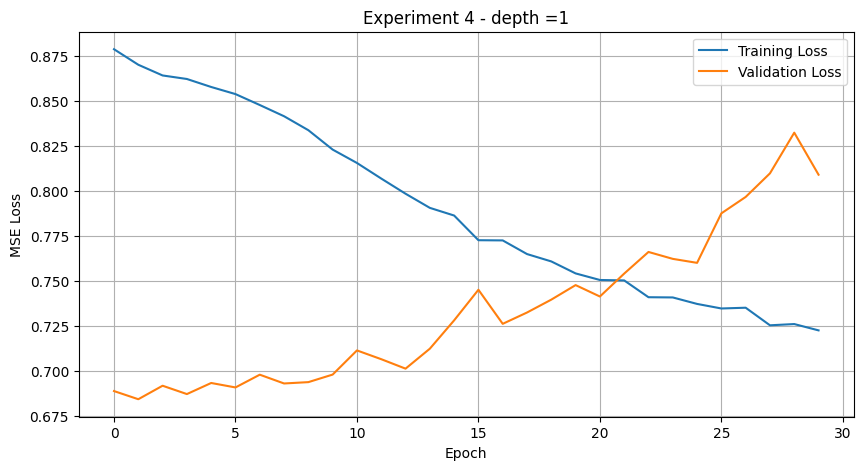

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp4_train_losses, label="Training Loss")
plt.plot(exp4_val_losses, label="Validation Loss")
plt.title("Experiment 4 - depth =1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 5:depth =2
#neurons=64
#learning rate=0.01
#create a DNN model
class Experiment5Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#2.create the model
exp5_model = Experiment5Model(input_size=315)
print(exp5_model)

#create dataloader
exp5_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp5_criterion = nn.MSELoss()

#define optimizer
exp5_optimizer = optim.Adam(exp5_model.parameters(), lr=0.01)

#number of epochs
exp5_epochs=30
print("Experiment 5 training setup completed!")

#store training and validation losses
exp5_train_losses = []
exp5_val_losses = []

#start training
import time
exp5_start_time = time.time()
for epoch in range(exp5_epochs):
    exp5_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp5_train_loader:
        predictions = exp5_model(X_batch)
        loss = exp5_criterion(predictions, y_batch)
        exp5_optimizer.zero_grad()
        loss.backward()
        exp5_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)
   #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp5_model.eval()
    with torch.no_grad():
        val_predictions = exp5_model(X_val_tensor)
        val_loss = exp5_criterion(val_predictions, y_val_tensor).item()

   #save losses
    exp5_train_losses.append(train_loss)
    exp5_val_losses.append(val_loss)

   #display results
    print(f"Epoch [{epoch+1}/{exp5_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

   #calculate training time
    exp5_training_time=(time.time() - exp5_start_time)
    print(f"Training time: {exp5_training_time:.2f} seconds")

#display final results
print("Experiment 5 completed!")

print("final training MSE:", exp5_train_losses[-1])
print("final validation MSE:", exp5_val_losses[-1])
print("training time:",round(exp5_training_time, 2), "seconds")

Experiment5Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 5 training setup completed!
Epoch [1/30], Train Loss: 0.8814, Val Loss: 0.6873
Training time: 2.13 seconds
Epoch [2/30], Train Loss: 0.8715, Val Loss: 0.6875
Training time: 4.27 seconds
Epoch [3/30], Train Loss: 0.8678, Val Loss: 0.6877
Training time: 6.43 seconds
Epoch [4/30], Train Loss: 0.8616, Val Loss: 0.6974
Training time: 9.38 seconds
Epoch [5/30], Train Loss: 0.8581, Val Loss: 0.6893
Training time: 12.54 seconds
Epoch [6/30], Train Loss: 0.8531, Val Loss: 0.6919
Training time: 14.80 seconds
Epoch [7/30], Train Loss: 0.8476, Val Loss: 0.6943
Training time: 16.99 seconds
Epoch [8/30], Train Loss: 0.8441, Val Loss: 0.7026
Training time: 19.17 seconds
Epoch [9/30], Train Loss: 0.8372, Val Loss: 0.6935
Training time

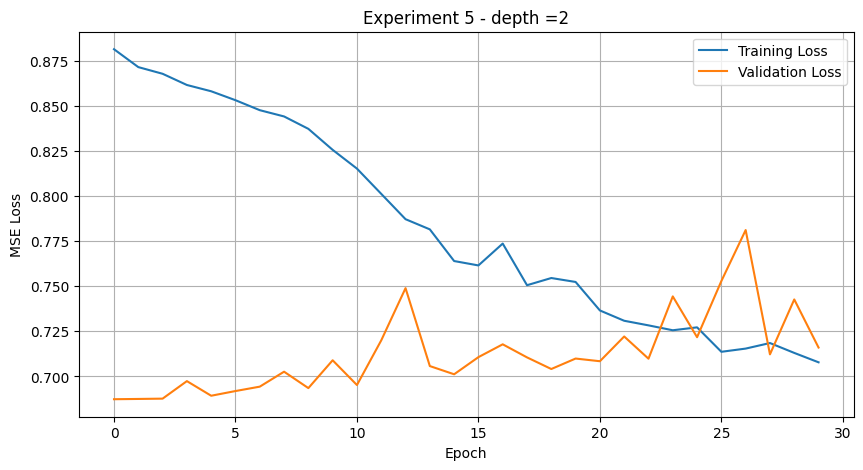

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp5_train_losses, label="Training Loss")
plt.plot(exp5_val_losses, label="Validation Loss")
plt.title("Experiment 5 - depth =2")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 6:depth=3
#neurons=64
#learning rate=0.01
#1.create a DNN model
class Experiment6Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#create the model
exp6_model = Experiment6Model(input_size=315)
print(exp6_model)

#create the Dataloader
exp6_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp6_criterion = nn.MSELoss()

#define optimizer
exp6_optimizer = optim.Adam(exp6_model.parameters(), lr=0.01)

#number of epochs
exp6_epochs=30
print("Experiment 6 training setup completed!")

#store training and validation losses
exp6_train_losses = []
exp6_val_losses = []

#start training
import time
exp6_start_time = time.time()
for epoch in range(exp6_epochs):
    exp6_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp6_train_loader:
        predictions = exp6_model(X_batch)
        loss = exp6_criterion(predictions, y_batch)
        exp6_optimizer.zero_grad()
        loss.backward()
        exp6_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp6_model.eval()
    with torch.no_grad():
      val_predictions = exp6_model(X_val_tensor)
      val_loss = exp6_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp6_train_losses.append(train_loss)
    exp6_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp6_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculate training time
    exp6_training_time=(time.time() - exp6_start_time)
    print(f"Training time: {exp6_training_time:.2f} seconds")

#display final results
print("Experiment 6 completed!")

print("final training MSE:", exp6_train_losses[-1])
print("final validation MSE:", exp6_val_losses[-1])
print("training time:",round(exp6_training_time, 2), "seconds")


Experiment6Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 6 training setup completed!
Epoch [1/30], Train Loss: 0.8806, Val Loss: 0.6842
Training time: 2.33 seconds
Epoch [2/30], Train Loss: 0.8720, Val Loss: 0.6933
Training time: 4.74 seconds
Epoch [3/30], Train Loss: 0.8661, Val Loss: 0.6947
Training time: 7.19 seconds
Epoch [4/30], Train Loss: 0.8651, Val Loss: 0.6893
Training time: 10.65 seconds
Epoch [5/30], Train Loss: 0.8597, Val Loss: 0.6949
Training time: 13.66 seconds
Epoch [6/30], Train Loss: 0.8547, Val Loss: 0.6858
Training time: 16.16 seconds
Epoch [7/30], Train Loss: 0.8525, Val Loss: 0.6940
Training time: 18.67 seconds
Epoch [8/30], Train Loss: 0.8514, Val Loss: 0.7041
Training time: 2

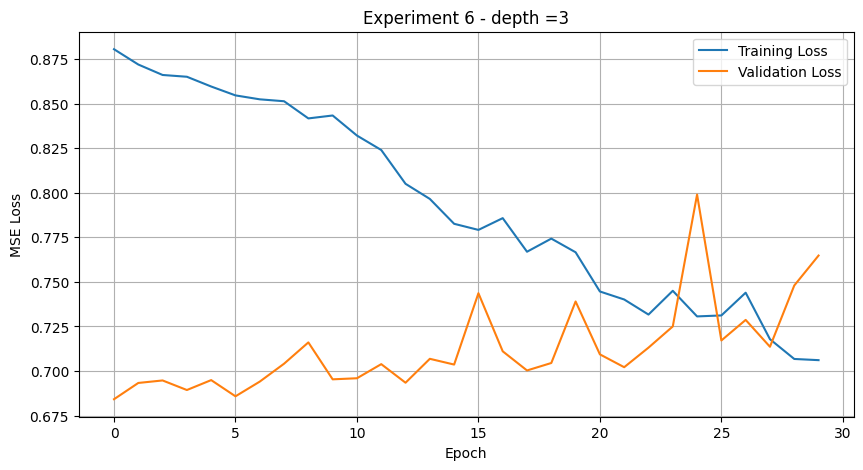

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp6_train_losses, label="Training Loss")
plt.plot(exp6_val_losses, label="Validation Loss")
plt.title("Experiment 6 - depth =3")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#new experiment*:depth=4, width=64
class Experiment00Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))


    def forward(self, x):
        return self.network(x)

#create the model
exp00_model = Experiment00Model(input_size=315)
print(exp00_model)

#dataloader
exp00_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#loss & optimizer
exp00_criterion = nn.MSELoss()
exp00_optimizer = optim.Adam(exp00_model.parameters(), lr=0.01)

#epochs
exp00_epochs=30
print("Experiment 00 training setup completed!")

#store losses
exp00_train_losses = []
exp00_val_losses = []

#start training
import time
exp00_start_time = time.time()
for epoch in range(exp00_epochs):
    exp00_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp00_train_loader:
        predictions = exp00_model(X_batch)
        loss = exp00_criterion(predictions, y_batch)
        exp00_optimizer.zero_grad()
        loss.backward()
        exp00_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp00_model.eval()
    with torch.no_grad():
      val_predictions = exp00_model(X_val_tensor)
      val_loss = exp00_criterion(val_predictions, y_val_tensor).item()

    exp00_train_losses.append(train_loss)
    exp00_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp00_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp00_training_time=(time.time() - exp00_start_time)
    print(f"Training time: {exp00_training_time:.2f} seconds")

#display final results
print("Experiment 00 completed!")

print("final training MSE:", exp00_train_losses[-1])
print("final validation MSE:", exp00_val_losses[-1])
print("training time:",round(exp00_training_time, 2), "seconds")


Experiment00Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 00 training setup completed!
Epoch [1/30], Train Loss: 0.8850, Val Loss: 0.6971
Training time: 2.90 seconds
Epoch [2/30], Train Loss: 0.8722, Val Loss: 0.6931
Training time: 5.72 seconds
Epoch [3/30], Train Loss: 0.8671, Val Loss: 0.6880
Training time: 8.68 seconds
Epoch [4/30], Train Loss: 0.8636, Val Loss: 0.6965
Training time: 12.42 seconds
Epoch [5/30], Train Loss: 0.8611, Val Loss: 0.7112
Training time: 15.89 seconds
Epoch [6/30], Train Loss: 0.8553, Val Loss: 0.6890
Training time: 18.85 seconds
Epoch [7/30], Train Loss: 0.8564, Val Loss: 0.7070
Training time: 21.

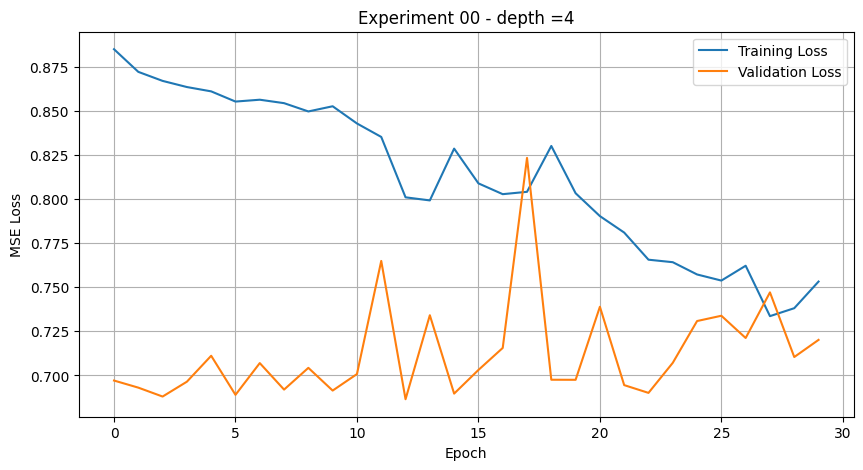

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp00_train_losses, label="Training Loss")
plt.plot(exp00_val_losses, label="Validation Loss")
plt.title("Experiment 00 - depth =4")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 7:MSE loss
#hidden layers=2
#neurons=64
#1.create a DNN model
class Experiment7Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#create the model
exp7_model = Experiment7Model(input_size=315)
print(exp7_model)

#create dataloader
exp7_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp7_criterion = nn.MSELoss()

#define optimizer
exp7_optimizer = optim.Adam(exp7_model.parameters(), lr=0.01)

#epochs
exp7_epochs= 30
print("Experiment 7 training setup completed!")

#store training and validation losses
exp7_train_losses = []
exp7_val_losses = []

#start training
import time
exp7_start_time = time.time()
for epoch in range(exp7_epochs):
    exp7_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp7_train_loader:
        predictions = exp7_model(X_batch)
        loss = exp7_criterion(predictions, y_batch)
        exp7_optimizer.zero_grad()
        loss.backward()
        exp7_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp7_model.eval()
    with torch.no_grad():
       val_predictions = exp7_model(X_val_tensor)
       val_loss = exp7_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp7_train_losses.append(train_loss)
    exp7_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp7_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculate training time
    exp7_training_time=(time.time() - exp7_start_time)
    print(f"Training time: {exp7_training_time:.2f} seconds")

#display final results
print("Experiment 7 completed!")

print("final training MSE:", exp7_train_losses[-1])
print("final validation MSE:", exp7_val_losses[-1])
print("training time:",round(exp7_training_time, 2), "seconds")

Experiment7Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 7 training setup completed!
Epoch [1/30], Train Loss: 0.8817, Val Loss: 0.6867
Training time: 2.10 seconds
Epoch [2/30], Train Loss: 0.8710, Val Loss: 0.6951
Training time: 4.25 seconds
Epoch [3/30], Train Loss: 0.8655, Val Loss: 0.6881
Training time: 6.42 seconds
Epoch [4/30], Train Loss: 0.8612, Val Loss: 0.6850
Training time: 9.31 seconds
Epoch [5/30], Train Loss: 0.8580, Val Loss: 0.6943
Training time: 12.33 seconds
Epoch [6/30], Train Loss: 0.8537, Val Loss: 0.6875
Training time: 14.54 seconds
Epoch [7/30], Train Loss: 0.8462, Val Loss: 0.6946
Training time: 16.76 seconds
Epoch [8/30], Train Loss: 0.8385, Val Loss: 0.7202
Training time: 19.00 seconds
Epoch [9/30], Train Loss: 0.8288, Val Loss: 0.7116
Training time

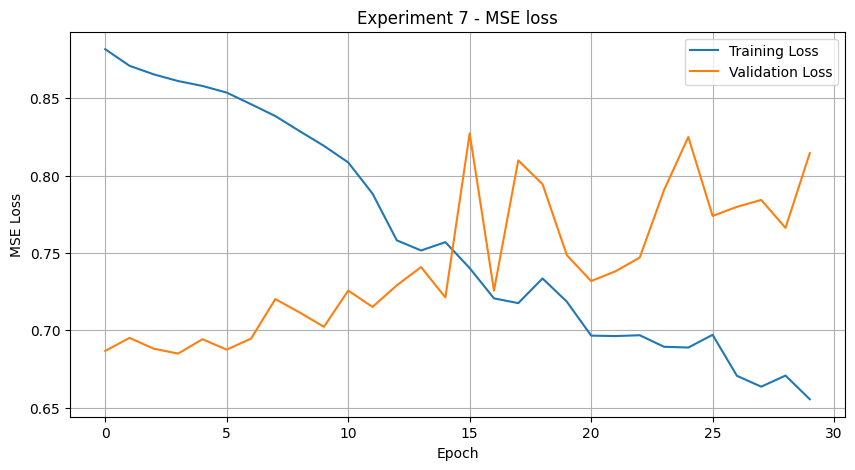

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp7_train_losses, label="Training Loss")
plt.plot(exp7_val_losses, label="Validation Loss")
plt.title("Experiment 7 - MSE loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 8:L1 loss
#hidden layers=2
#neurons=64
#1.create a DNN model
class Experiment8Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#create the model
exp8_model = Experiment8Model(input_size=315)
print(exp8_model)

#create dataloader
exp8_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp8_criterion = nn.L1Loss()
exp8_mse_criterion = nn.MSELoss()

#define optimizer
exp8_optimizer = optim.Adam(exp8_model.parameters(), lr=0.01)

#epochs
exp8_epochs=30
print("Experiment 8 training setup completed!")

#store training and validation losses
exp8_train_losses = []
exp8_val_losses = []
exp8_val_mse_scores = []

#start training
import time
exp8_start_time = time.time()
for epoch in range(exp8_epochs):
    exp8_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp8_train_loader:
        predictions = exp8_model(X_batch)
        loss = exp8_criterion(predictions, y_batch)
        exp8_optimizer.zero_grad()
        loss.backward()
        exp8_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp8_model.eval()
    with torch.no_grad():
      val_predictions = exp8_model(X_val_tensor)
      val_loss = exp8_criterion(val_predictions, y_val_tensor).item()
      val_mse = exp8_mse_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp8_train_losses.append(train_loss)
    exp8_val_losses.append(val_loss)
    exp8_val_mse_scores.append(val_mse)

    #display results
    print(f"Epoch [{epoch+1}/{exp8_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val MSE: {val_mse:.4f}")

    #calculate training time
    exp8_training_time=(time.time() - exp8_start_time)
    print(f"Training time: {exp8_training_time:.2f} seconds")

#display final results
print("Experiment 8 completed!")

print("final training L1 Loss:", exp8_train_losses[-1])
print("final validation L1 Loss:", exp8_val_losses[-1])
print("final validation MSE:", exp8_val_mse_scores[-1])
print("training time:",round(exp8_training_time, 2), "seconds")

Experiment8Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 8 training setup completed!
Epoch [1/30], Train Loss: 0.2249, Val Loss: 0.2259, Val MSE: 0.7076
Training time: 3.13 seconds
Epoch [2/30], Train Loss: 0.2198, Val Loss: 0.2218, Val MSE: 0.6900
Training time: 5.30 seconds
Epoch [3/30], Train Loss: 0.2186, Val Loss: 0.2201, Val MSE: 0.6969
Training time: 7.50 seconds
Epoch [4/30], Train Loss: 0.2179, Val Loss: 0.2344, Val MSE: 0.7215
Training time: 9.72 seconds
Epoch [5/30], Train Loss: 0.2176, Val Loss: 0.2226, Val MSE: 0.7069
Training time: 12.51 seconds
Epoch [6/30], Train Loss: 0.2165, Val Loss: 0.2213, Val MSE: 0.7035
Training time: 15.64 seconds
Epoch [7/30], Train Loss: 0.2160, Val Loss: 0.2238, Val MSE: 0.7163
Training time: 17.85 seconds
Epoch [8/30], Train Loss:

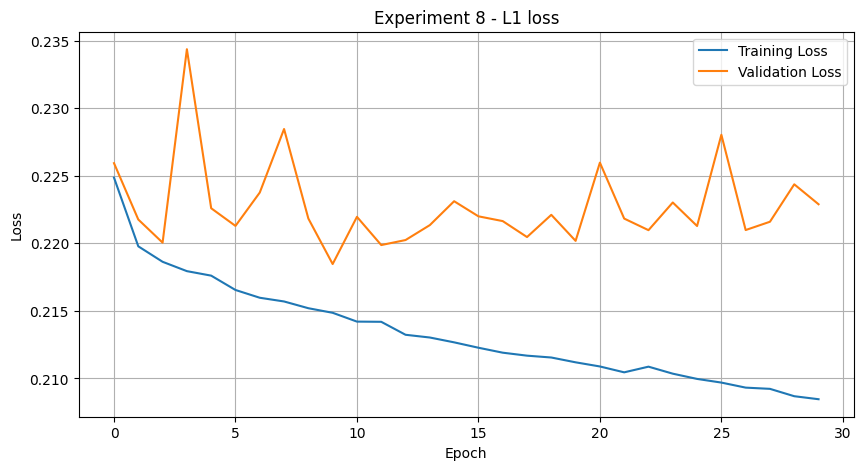

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp8_train_losses, label="Training Loss")
plt.plot(exp8_val_losses, label="Validation Loss")
plt.title("Experiment 8 - L1 loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 9:huber loss(delta=0.5)
#hidden layers=2
#neurons=64
#1.create a DNN model
class Experiment9Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#create the model
exp9_model = Experiment9Model(input_size=315)
print(exp9_model)

#create dataloader
exp9_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp9_criterion = nn.HuberLoss(delta=0.5)

#define optimizer
exp9_optimizer = optim.Adam(exp9_model.parameters(), lr=0.01)

#epochs
exp9_epochs= 30
print("Experiment 9 training setup completed!")

#store training and validation losses
exp9_train_losses = []
exp9_val_losses = []

#start training
import time
exp9_start_time = time.time()
for epoch in range(exp9_epochs):
    exp9_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp9_train_loader:
        predictions = exp9_model(X_batch)
        loss = exp9_criterion(predictions, y_batch)
        exp9_optimizer.zero_grad()
        loss.backward()
        exp9_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp9_model.eval()
    with torch.no_grad():
      val_predictions = exp9_model(X_val_tensor)
      val_loss = exp9_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp9_train_losses.append(train_loss)
    exp9_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp9_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculate training time
    exp9_training_time = time.time() - exp9_start_time
    print(f"training time: {exp9_training_time:.2f} seconds")

#final results
print("Experiment 9 completed!")

print("final training loss:", exp9_train_losses[-1])
print("final validation loss:", exp9_val_losses[-1])
print("training time:",round(exp9_training_time, 2), "seconds")


Experiment9Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 9 training setup completed!
Epoch [1/30], Train Loss: 0.0610, Val Loss: 0.0606
training time: 2.08 seconds
Epoch [2/30], Train Loss: 0.0598, Val Loss: 0.0603
training time: 5.18 seconds
Epoch [3/30], Train Loss: 0.0595, Val Loss: 0.0605
training time: 7.92 seconds
Epoch [4/30], Train Loss: 0.0594, Val Loss: 0.0597
training time: 10.14 seconds
Epoch [5/30], Train Loss: 0.0590, Val Loss: 0.0597
training time: 12.33 seconds
Epoch [6/30], Train Loss: 0.0589, Val Loss: 0.0600
training time: 14.53 seconds
Epoch [7/30], Train Loss: 0.0586, Val Loss: 0.0601
training time: 16.99 seconds
Epoch [8/30], Train Loss: 0.0584, Val Loss: 0.0611
training time: 22.57 seconds
Epoch [9/30], Train Loss: 0.0585, Val Loss: 0.0600
training tim

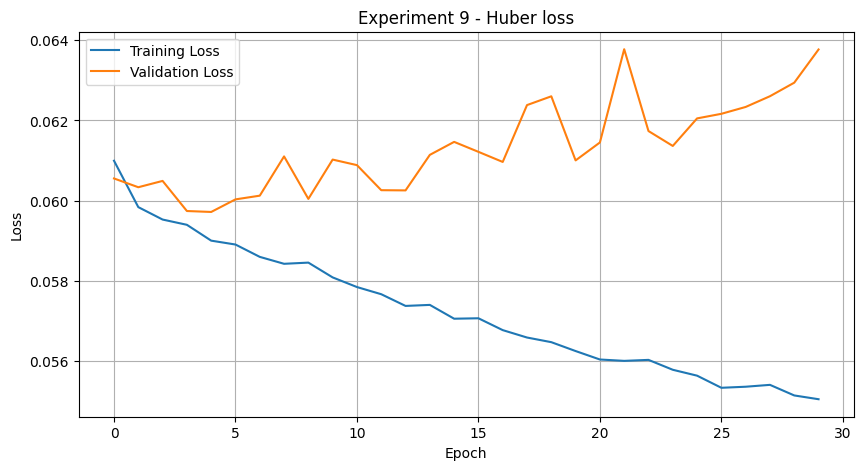

In [ ]:
#plot training and validation loss
plt.figure(figsize=(10,5))
plt.plot(exp9_train_losses, label="Training Loss")
plt.plot(exp9_val_losses, label="Validation Loss")
plt.title("Experiment 9 - Huber loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 10:huber loss(delta=1.0)
class Experiment10Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#creat model
exp10_model = Experiment10Model(input_size=315)
print(exp10_model)

#create dataloader
exp10_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function and optimizer
exp10_criterion=nn.HuberLoss(delta=1.0)
exp10_optimizer = optim.Adam(exp10_model.parameters(), lr=0.01)

#epochs
exp10_epochs=30
print("Experiment 10 training setup completed!")

#store training and validation losses
exp10_train_losses = []
exp10_val_losses = []

#start training
import time
exp10_start_time = time.time()
for epoch in range(exp10_epochs):
    exp10_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp10_train_loader:
        predictions = exp10_model(X_batch)
        loss = exp10_criterion(predictions, y_batch)
        exp10_optimizer.zero_grad()
        loss.backward()
        exp10_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss= total_train_loss / len(train_dataset)


    #validation
    exp10_model.eval()
    with torch.no_grad():
      val_predictions = exp10_model(X_val_tensor)
      val_loss = exp10_criterion(val_predictions, y_val_tensor).item()

    exp10_train_losses.append(train_loss)
    exp10_val_losses.append(val_loss)

    #results
    print(f"Epoch [{epoch+1}/{exp10_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp10_training_time=(time.time() - exp10_start_time)
    print(f"Training time: {exp10_training_time:.2f} seconds")

#final results
print("Experiment 10 completed!")

print("final training loss:", exp10_train_losses[-1])
print("final validation loss:", exp10_val_losses[-1])
print("training time:",round(exp10_training_time, 2), "seconds")

Experiment10Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 10 training setup completed!
Epoch [1/30], Train Loss: 0.0948, Val Loss: 0.0937
Training time: 4.49 seconds
Epoch [2/30], Train Loss: 0.0932, Val Loss: 0.0923
Training time: 8.57 seconds
Epoch [3/30], Train Loss: 0.0926, Val Loss: 0.0929
Training time: 14.50 seconds
Epoch [4/30], Train Loss: 0.0920, Val Loss: 0.0930
Training time: 19.38 seconds
Epoch [5/30], Train Loss: 0.0917, Val Loss: 0.0955
Training time: 21.63 seconds
Epoch [6/30], Train Loss: 0.0916, Val Loss: 0.0926
Training time: 23.82 seconds
Epoch [7/30], Train Loss: 0.0910, Val Loss: 0.0934
Training time: 30.44 seconds
Epoch [8/30], Train Loss: 0.0909, Val Loss: 0.0935
Training time: 33.59 seconds
Epoch [9/30], Train Loss: 0.0905, Val Loss: 0.0931
Training 

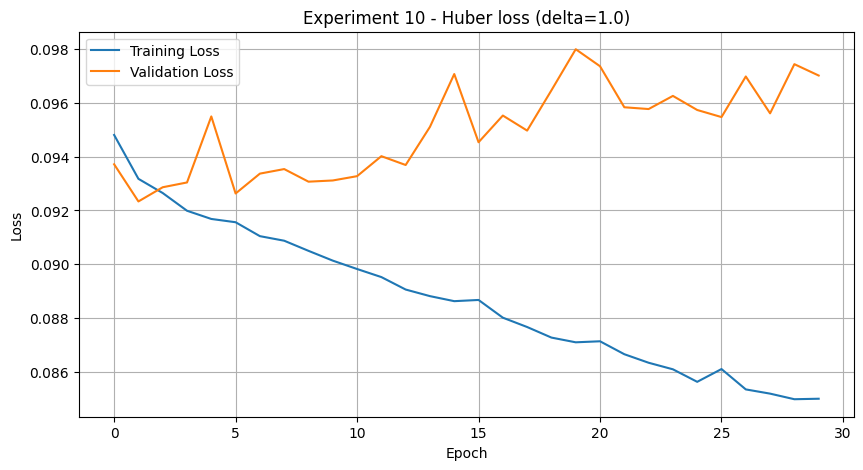

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp10_train_losses, label="Training Loss")
plt.plot(exp10_val_losses, label="Validation Loss")
plt.title("Experiment 10 - Huber loss (delta=1.0)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Experiment 11:Huber loss(delta=2.0)
class Experiment11Model(nn.Module):
  def __init__(self, input_size):
    super().__init__()
    self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

  def forward(self, x):
    return self.network(x)

#create model
exp11_model = Experiment11Model(input_size=315)
print(exp11_model)

#dataloader
exp11_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp11_criterion = nn.HuberLoss(delta=2.0)

#define optimizer
exp11_optimizer = optim.Adam(exp11_model.parameters(), lr=0.01)

#epochs
exp11_epochs=30
print("Experiment 11 training setup completed!")

#store training and validation losses
exp11_train_losses = []
exp11_val_losses = []

#start training
exp11_start_time = time.time()
for epoch in range(exp11_epochs):
    exp11_model.train()
    total_train_loss =0

    for X_batch, y_batch in exp11_train_loader:
        predictions = exp11_model(X_batch)
        loss = exp11_criterion(predictions, y_batch)
        exp11_optimizer.zero_grad()
        loss.backward()
        exp11_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss=total_train_loss/len(train_dataset)

    #validation
    exp11_model.eval()
    with torch.no_grad():
      val_predictions = exp11_model(X_val_tensor)
      val_loss = exp11_criterion(val_predictions, y_val_tensor).item()

    exp11_train_losses.append(train_loss)
    exp11_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp11_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp11_training_time=(time.time() - exp11_start_time)
    print(f"Training time: {exp11_training_time:.2f} seconds")

#results
print("Experiment 11 completed!")

print("final training loss:", exp11_train_losses[-1])
print("final validation loss:", exp11_val_losses[-1])
print("training time:",round(exp11_training_time, 2), "seconds")

Experiment11Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 11 training setup completed!
Epoch [1/30], Train Loss: 0.1407, Val Loss: 0.1370
Training time: 4.27 seconds
Epoch [2/30], Train Loss: 0.1382, Val Loss: 0.1358
Training time: 6.62 seconds
Epoch [3/30], Train Loss: 0.1373, Val Loss: 0.1360
Training time: 8.78 seconds
Epoch [4/30], Train Loss: 0.1368, Val Loss: 0.1382
Training time: 11.07 seconds
Epoch [5/30], Train Loss: 0.1362, Val Loss: 0.1365
Training time: 16.24 seconds
Epoch [6/30], Train Loss: 0.1358, Val Loss: 0.1371
Training time: 20.77 seconds
Epoch [7/30], Train Loss: 0.1353, Val Loss: 0.1411
Training time: 25.95 seconds
Epoch [8/30], Train Loss: 0.1358, Val Loss: 0.1369
Training time: 31.85 seconds
Epoch [9/30], Train Loss: 0.1343, Val Loss: 0.1363
Training t

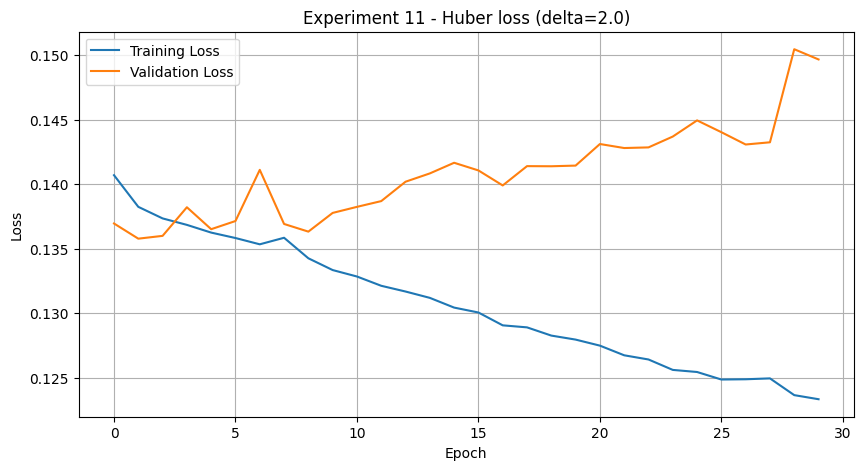

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp11_train_losses, label="Training Loss")
plt.plot(exp11_val_losses, label="Validation Loss")
plt.title("Experiment 11 - Huber loss (delta=2.0)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#experiment 12:Huber loss(delta=0.25)
class Experiment12Model(nn.Module):
  def __init__(self, input_size):
    super().__init__()
    self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.Linear(64,1))

  def forward(self, x):
    return self.network(x)

#create model
exp12_model = Experiment12Model(input_size=315)
print(exp12_model)

#dataloader
exp12_train_loader=DataLoader(train_dataset,batch_size=256,shuffle=True)

#loss function and optimizer
exp12_criterion = nn.HuberLoss(delta=0.25)
exp12_optimizer = optim.Adam(exp12_model.parameters(), lr=0.01)

#epochs
exp12_epochs=30
print("Experiment 12 training setup completed!")

#store training and validation losses
exp12_train_losses = []
exp12_val_losses = []

#start training
import time
exp12_start_time = time.time()
for epoch in range(exp12_epochs):
    exp12_model.train()
    total_train_loss =0
    for X_batch, y_batch in exp12_train_loader:
        predictions = exp12_model(X_batch)
        loss = exp12_criterion(predictions, y_batch)
        exp12_optimizer.zero_grad()
        loss.backward()
        exp12_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss=total_train_loss/len(train_dataset)

    #validation
    exp12_model.eval()
    with torch.no_grad():
      val_predictions = exp12_model(X_val_tensor)
      val_loss = exp12_criterion(val_predictions, y_val_tensor).item()

    exp12_train_losses.append(train_loss)
    exp12_val_losses.append(val_loss)

    #results
    print(f"Epoch [{epoch+1}/{exp12_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp12_training_time=(time.time() - exp12_start_time)
    print(f"Training time: {exp12_training_time:.2f} seconds")

#final results
print("Experiment 12 completed!")

print("final training loss:", exp12_train_losses[-1])
print("final validation loss:", exp12_val_losses[-1])
print("training time:",round(exp12_training_time, 2), "seconds")


Experiment12Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 12 training setup completed!
Epoch [1/30], Train Loss: 0.0378, Val Loss: 0.0383
Training time: 6.13 seconds
Epoch [2/30], Train Loss: 0.0371, Val Loss: 0.0371
Training time: 11.02 seconds
Epoch [3/30], Train Loss: 0.0369, Val Loss: 0.0370
Training time: 15.54 seconds
Epoch [4/30], Train Loss: 0.0367, Val Loss: 0.0372
Training time: 20.53 seconds
Epoch [5/30], Train Loss: 0.0367, Val Loss: 0.0378
Training time: 24.69 seconds
Epoch [6/30], Train Loss: 0.0366, Val Loss: 0.0370
Training time: 31.07 seconds
Epoch [7/30], Train Loss: 0.0365, Val Loss: 0.0372
Training time: 34.86 seconds
Epoch [8/30], Train Loss: 0.0363, Val Loss: 0.0371
Training time: 37.13 seconds
Epoch [9/30], Train Loss: 0.0364, Val Loss: 0.0375
Training time: 39.45 sec

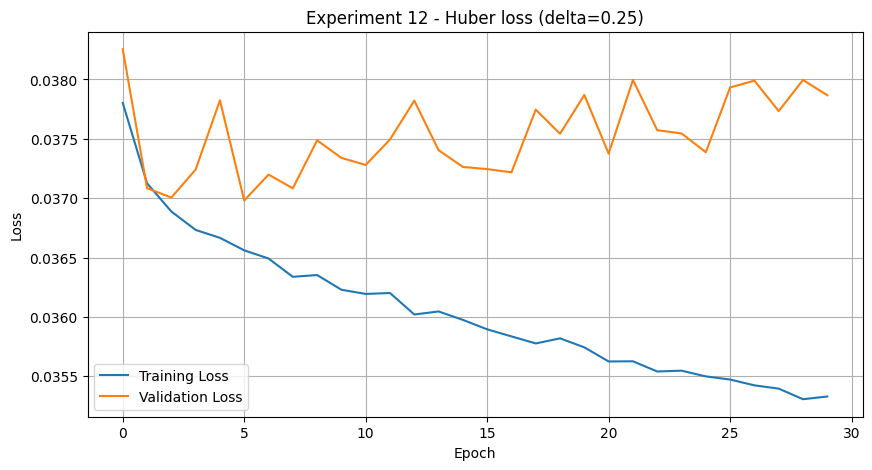

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp12_train_losses, label="Training Loss")
plt.plot(exp12_val_losses, label="Validation Loss")
plt.title("Experiment 12 - Huber loss (delta=0.25)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#experiment 13:batch size=64
class Experiment13Model(nn.Module):
  def __init__(self, input_size):
    super().__init__()
    self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,1))

  def forward(self, x):
    return self.network(x)

#create model
exp13_model = Experiment13Model(input_size=315)
print(exp13_model)

#dataloader
exp13_train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)

#loss function and optimizer
exp13_criterion = nn.HuberLoss(delta=0.25)
exp13_optimizer = optim.Adam(exp13_model.parameters(), lr=0.01)

#epochs
exp13_epochs= 30
print("Experiment 13 training setup completed!")

#store training and validation losses
exp13_train_losses = []
exp13_val_losses = []

#training
import time
exp13_start_time = time.time()
for epoch in range(exp13_epochs):
    exp13_model.train()
    total_train_loss =0
    for X_batch, y_batch in exp13_train_loader:
        predictions = exp13_model(X_batch)
        loss = exp13_criterion(predictions, y_batch)
        exp13_optimizer.zero_grad()
        loss.backward()
        exp13_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp13_model.eval()
    with torch.no_grad():
      val_predictions = exp13_model(X_val_tensor)
      val_loss = exp13_criterion(val_predictions, y_val_tensor).item()

    exp13_train_losses.append(train_loss)
    exp13_val_losses.append(val_loss)

    #results
    print(f"Epoch [{epoch+1}/{exp13_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #training time
    exp13_training_time=(time.time() - exp13_start_time)
    print(f"Training time: {exp13_training_time:.2f} seconds")

#final results
print("Experiment 13 completed!")
print("final training loss:", exp13_train_losses[-1])
print("final validation loss:", exp13_val_losses[-1])
print("training time:",round(exp13_training_time, 2), "seconds")


Experiment13Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Experiment 13 training setup completed!
Epoch [1/30], Train Loss: 0.0379, Val Loss: 0.0375
Training time: 11.83 seconds
Epoch [2/30], Train Loss: 0.0372, Val Loss: 0.0377
Training time: 21.75 seconds
Epoch [3/30], Train Loss: 0.0371, Val Loss: 0.0371
Training time: 30.80 seconds
Epoch [4/30], Train Loss: 0.0370, Val Loss: 0.0370
Training time: 41.43 seconds
Epoch [5/30], Train Loss: 0.0368, Val Loss: 0.0374
Training time: 46.57 seconds
Epoch [6/30], Train Loss: 0.0368, Val Loss: 0.0372
Training time: 52.65 seconds
Epoch [7/30], Train Loss: 0.0367, Val Loss: 0.0374
Training time: 57.82 seconds
Epoch [8/30], Train Loss: 0.0366, Val Loss: 0.0376
Training time: 64.03 seconds
Epoch [9/30], Train Loss: 0.0365, Val Loss: 0.0371
Trainin

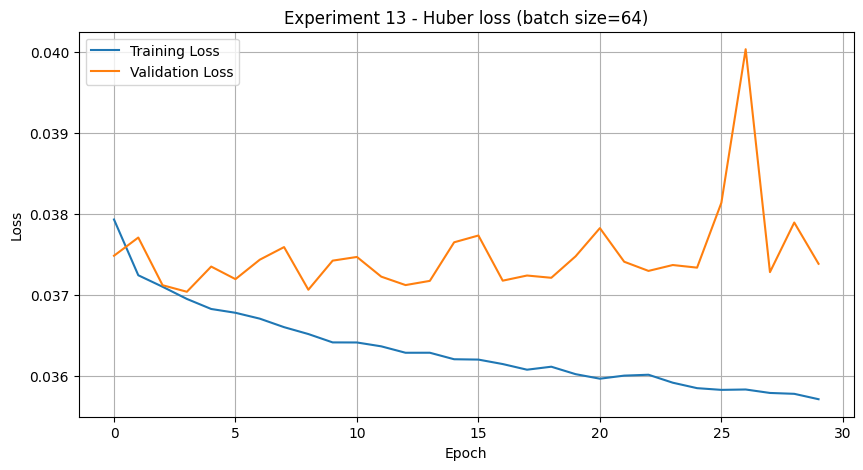

In [ ]:
#plotting cell
plt.figure(figsize=(10,5))
plt.plot(exp13_train_losses, label="Training Loss")
plt.plot(exp13_val_losses, label="Validation Loss")
plt.title("Experiment 13 - Huber loss (batch size=64)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()